# 상태 갱신

**이 노트북에서 할 일**

1. 01절 상태 형식을 다시 적고 노드 두 개가 자기 이름만 내놓도록 바꿉니다.
2. 규칙이 없는 칸에 갱신 두 개가 모이면 무엇이 남는지 봅니다.
3. 실행 흔적 칸에 이어 붙이기 규칙을 적고 같은 두 노드로 다시 실행합니다.
4. 처음 실행 흔적과 노드가 내놓는 모양을 하나씩 바꿔 네 실행을 견줍니다.

**준비물** — 이 절은 OpenAI API 키를 쓰지 않습니다.
모델 요청이 0번이라 드는 비용이 없습니다.
읽어 오는 자료 파일도 없고 새로 쓰는 파일도 없습니다.
실행 시간은 1분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangGraph 1.2.11과 도구 파일이 쓰는 numpy 2.5.3을 설치합니다.
실습 폴더 잠금 파일은 LangChain 1.4.0도 함께 고정하지만 이 절은 부르지 않습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
상태 형식에 규칙을 적고 같은 두 노드로 두 번 실행하는 자리입니다.
8절과 9절은 값을 하나씩 바꿔 보는 자리입니다.
10절은 네 실행을 기록 한 줄씩으로 만들어 표로 견주는 자리입니다.
준비부터 끝까지 함께 실행하고 실습 시간에 다시 읽습니다.

실습 폴더 `labs/part4/ch13-langgraph-basics`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![왼쪽부터 오른쪽으로 놓인 칸 두 개와 회색 상자 하나로 왼쪽 칸 제목은 규칙이 없는 실행 흔적 칸이고 그 안에 파란 상자 받은 갱신 둘 normalize 다음 make_query와 노란 상자 남은 값 make_query 하나가 있으며 가운데 칸 제목은 규칙을 적은 실행 흔적 칸이고 그 안에 파란 상자 받은 갱신 둘 normalize 다음 make_query와 노란 상자 남은 값 normalize 다음 make_query가 있고 오른쪽에 회색 상자 두 칸이 받은 갱신은 같았음이 놓인 그림](attachment:02-1-칸에-적은-규칙.png)

왼쪽 칸과 가운데 칸의 위 파란 상자가 같습니다.
두 칸이 받은 갱신이 같다는 뜻입니다.
아래 노란 상자의 값이 서로 다릅니다.
칸에 적은 규칙이 남는 값을 갈랐습니다.
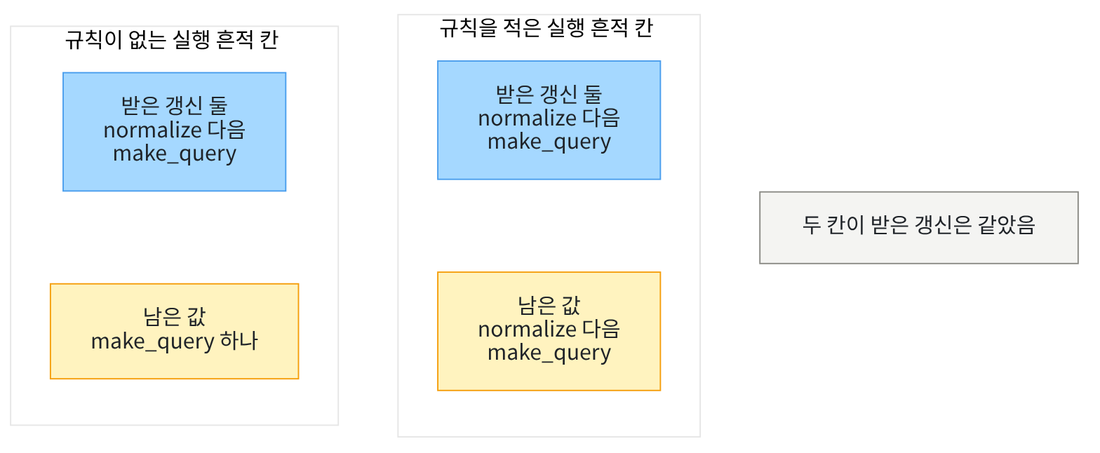

## 1. 준비

첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "numpy==2.5.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 `langgraph: 1.2.11`과 `numpy: 2.5.3`이 보입니다.
패키지 `numpy`는 이 절이 직접 쓰지 않지만 도구 파일을 불러올 때 필요합니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이름 여섯 개를 불러옵니다.
앞의 네 개는 01절에서 쓴 이름이고 뒤의 두 개가 이 절에서 처음 쓰는 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 01절 출력 함수 `print_state()`를 가져옵니다.
라벨 줄을 따로 출력하고 그 아래에 칸 셋을 한 줄씩 적는 함수입니다.

In [2]:
# 01절에서 쓴 이름 네 개에 규칙을 적는 데 쓸 이름 두 개를 더해 불러옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
# 01절에서 만든 출력 함수를 도구 파일에서 가져옵니다
from rag_tools import print_state

print("불러온 이름:", "operator", "Annotated", "TypedDict", "StateGraph", "START", "END")

불러온 이름: operator Annotated TypedDict StateGraph START END


**결과 읽기** — 출력 줄은 `불러온 이름: operator Annotated TypedDict StateGraph START END` 하나입니다.
꾸러미 `operator`에는 더하기 같은 기본 연산을 함수로 담아 둔 이름이 들어 있습니다.
표시 `Annotated`는 값 갈래 옆에 함께 쓸 정보를 적어 두는 표시입니다.
두 이름을 쓰는 자리는 6절과 7절입니다.
도구 파일에서 가져온 함수는 출력하지 않습니다.

## 2. 이 절에서 쓸 값 정하기

01절에서 쓴 첫 질문을 글자까지 같게 씁니다.
나중에 처음 실행 흔적으로 넣어 볼 목록도 미리 만들어 둡니다.

In [3]:
# 01절에서 쓴 첫 질문과 이 절에서 넣어 볼 처음 실행 흔적을 정합니다
first_question = "  대출 기간은 며칠인가요?  "
started_trace = ["input"]
print("첫 질문:", first_question)
print("첫 질문의 글자 수:", len(first_question))
print("나중에 넣어 볼 처음 실행 흔적:", started_trace)

첫 질문:   대출 기간은 며칠인가요?  
첫 질문의 글자 수: 17
나중에 넣어 볼 처음 실행 흔적: ['input']


**결과 읽기** — 출력 줄 `첫 질문의 글자 수: 17`은 01절과 같은 값입니다.
앞뒤 빈칸 네 개가 함께 세어진 수입니다.
출력 줄 `나중에 넣어 볼 처음 실행 흔적: ['input']`의 목록은 8절에서 씁니다.

## 3. 01절 상태 형식 다시 적기

01절 상태 형식에는 칸이 셋 있었고 어느 칸에도 규칙을 적지 않았습니다.
이 절에서도 그 형식으로 먼저 실행합니다.
이 절은 여기에 규칙 한 줄을 더하는 자리입니다.

In [4]:
# 01절에서 적은 규칙 없는 상태 형식을 이 절에서도 먼저 씁니다
class FlowState(TypedDict):
    question: str
    query: str
    trace: list[str]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 이름 뒤에 값 갈래만 적혀 있습니다.
칸 `trace`에는 지나간 노드 이름을 차례로 담습니다.
출력 함수 `print_state()`는 준비 셀에서 가져온 01절 판을 그대로 씁니다.

## 4. 노드 두 개 — 자기 이름만 내놓기

01절 두 노드는 실행 흔적을 낼 때 `state["trace"] + ["이름"]`으로 앞 값을 함께 담았습니다.
이번에는 두 노드 모두 자기 이름 하나만 담아 냅니다.
앞 값을 어떻게 이어 붙일지는 노드가 아니라 칸이 정하게 할 참입니다.

In [5]:
# 질문 칸의 앞뒤 빈칸을 없애고 실행 흔적에는 자기 이름만 담아 냅니다
def normalize(state):
    clean_question = state["question"].strip()
    return {"question": clean_question, "trace": ["normalize"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `strip()`은 글 앞뒤의 빈칸을 없앱니다.
실행 흔적 칸에 담아 내는 목록에는 이름 하나만 들어 있습니다.

다음 셀은 검색어 칸을 만드는 노드입니다.

In [6]:
# 물음표와 맺음말을 지워 검색어를 만들고 실행 흔적에는 자기 이름만 담아 냅니다
def make_query(state):
    without_mark = state["question"].replace("?", "")
    plain = without_mark.replace("인가요", "")
    return {"query": plain.strip(), "trace": ["make_query"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `replace()`는 글에서 찾은 말을 다른 말로 바꿉니다.
여기서는 물음표와 맺음말 `인가요`를 빈 글로 바꿔 지웁니다.

## 5. 실행 1 — 규칙이 없는 칸

먼저 규칙을 적지 않은 상태 형식으로 그래프를 만듭니다.
노드 두 개와 엣지 세 개는 01절과 같습니다.

In [7]:
# 규칙이 없는 상태 형식으로 노드 두 개와 엣지 세 개를 적어 컴파일합니다
plain_builder = StateGraph(FlowState)
plain_builder.add_node("normalize", normalize)
plain_builder.add_node("make_query", make_query)
plain_builder.add_edge(START, "normalize")
plain_builder.add_edge("normalize", "make_query")
plain_builder.add_edge("make_query", END)
plain_graph = plain_builder.compile()
print("등록한 노드 수:", len(plain_builder.nodes))
print("컴파일 결과의 종류:", type(plain_graph))

등록한 노드 수: 2
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 `등록한 노드 수: 2`와 종류 이름 `CompiledStateGraph`가 보입니다.
01절에서 만든 그래프와 같은 모양입니다.

실행 전에 예상해 봅니다.
두 노드가 실행 흔적 칸에 갱신을 하나씩 내니 이름 두 개가 남을 것도 같습니다.

In [8]:
# 규칙이 없는 상태 형식의 그래프에 첫 질문을 넣어 실행합니다
plain_state = {"question": first_question, "query": "", "trace": []}
plain_result = plain_graph.invoke(plain_state)
print_state("규칙이 없는 칸 결과", plain_result)
print("실행 흔적 칸의 길이:", len(plain_result["trace"]))

규칙이 없는 칸 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
실행 흔적 칸 | ['make_query']
실행 흔적 칸의 길이: 1


**결과 읽기** — 줄 `실행 흔적 칸 | ['make_query']`에 이름이 하나뿐입니다.
출력 줄 `실행 흔적 칸의 길이: 1`이 그 수입니다.
먼저 온 갱신 `['normalize']`는 남지 않았습니다.
규칙을 적지 않은 칸은 마지막에 온 갱신으로 값을 바꿉니다.
줄 `검색어 칸 | 대출 기간은 며칠`은 01절과 같은 값입니다.

## 6. 칸에 적을 규칙 읽어 보기

리듀서(reducer)는 칸의 지금 값과 새 갱신을 받아 그 칸의 다음 값을 만드는 함수입니다.
공용 게시판의 칸마다 「새 쪽지로 바꾸기」와 「아래에 덧붙이기」 중 하나를 미리 정해 둔 것과 같습니다.
이 절에서는 목록 두 개를 이어 붙이는 함수 하나를 리듀서로 씁니다.
다음 셀은 그 함수를 그래프 없이 직접 불러 봅니다.

In [9]:
# 규칙으로 적을 operator.add가 목록 두 개에 무엇을 하는지 먼저 봅니다
left_trace = ["input"]
right_trace = ["normalize"]
joined_trace = operator.add(left_trace, right_trace)
print("왼쪽 목록:", left_trace)
print("오른쪽 목록:", right_trace)
print("operator.add가 만든 목록:", joined_trace)

왼쪽 목록: ['input']
오른쪽 목록: ['normalize']
operator.add가 만든 목록: ['input', 'normalize']


**결과 읽기** — 출력 줄 `operator.add가 만든 목록: ['input', 'normalize']`가 보입니다.
함수 `operator.add`는 값 두 개를 받아 더하기 기호와 같은 방법으로 합칩니다.
숫자 둘이면 더한 수가 되고 목록 둘이면 앞뒤로 이어 붙인 목록이 됩니다.
왼쪽 목록과 오른쪽 목록은 그대로 있고 새 목록이 따로 만들어졌습니다.

다음 셀은 그 함수를 실행 흔적 칸의 규칙으로 적습니다.
표시 `Annotated`는 값 갈래 옆에 함께 쓸 정보를 적어 두는 표시입니다.
짐 상자에 「깨지기 쉬움」처럼 다루는 방법을 함께 붙여 두는 것과 같습니다.
표시 `Annotated[list[str], operator.add]`는 「문자열 목록인데 합칠 때는 이 함수로」라는 뜻입니다.

In [10]:
# 실행 흔적 칸에만 이어 붙이기 규칙을 적은 상태 형식을 만듭니다
class RuleState(TypedDict):
    question: str
    query: str
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `question`과 칸 `query`에는 규칙을 적지 않았습니다.
칸 `trace`에만 규칙을 적었습니다.
칸마다 규칙을 따로 정할 수 있습니다.

## 7. 실행 2 — 규칙을 적은 칸

바꾼 것은 상태 형식 하나입니다.
노드 두 개와 엣지 세 개와 질문은 그대로 둡니다.
실행 전에 예상해 봅니다. 실행 흔적 칸에 이름 두 개가 남을 것입니다.

In [11]:
# 같은 노드 두 개와 같은 엣지 세 개를 규칙 적은 상태 형식으로 다시 적습니다
rule_builder = StateGraph(RuleState)
rule_builder.add_node("normalize", normalize)
rule_builder.add_node("make_query", make_query)
rule_builder.add_edge(START, "normalize")
rule_builder.add_edge("normalize", "make_query")
rule_builder.add_edge("make_query", END)
rule_graph = rule_builder.compile()
print("노드 수가 앞 그래프와 같은가:", len(rule_builder.nodes) == len(plain_builder.nodes))
print("컴파일 결과의 종류:", type(rule_graph))

노드 수가 앞 그래프와 같은가: True
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 `노드 수가 앞 그래프와 같은가: True`가 보입니다.
종류 이름도 `CompiledStateGraph`로 앞 그래프와 같습니다.

다음 셀은 같은 첫 질문을 넣어 실행합니다.

In [12]:
# 규칙을 적은 상태 형식의 그래프에 같은 첫 질문을 넣어 실행합니다
rule_state = {"question": first_question, "query": "", "trace": []}
rule_result = rule_graph.invoke(rule_state)
print_state("규칙을 적은 칸 결과", rule_result)
print("실행 흔적 칸의 길이:", len(rule_result["trace"]))

규칙을 적은 칸 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
실행 흔적 칸 | ['normalize', 'make_query']
실행 흔적 칸의 길이: 2


**결과 읽기** — 줄 `실행 흔적 칸 | ['normalize', 'make_query']`에 이름 두 개가 차례로 남았습니다.
출력 줄 `실행 흔적 칸의 길이: 2`가 그 수입니다.
노드는 자기 이름 하나만 냈는데 칸에 적은 규칙이 앞 값과 이어 붙였습니다.

다음 셀은 두 실행을 칸별로 견줍니다.

In [13]:
# 두 실행의 결과를 칸별로 견줍니다
print("질문 칸이 같은가:", plain_result["question"] == rule_result["question"])
print("검색어 칸이 같은가:", plain_result["query"] == rule_result["query"])
print("실행 흔적 칸이 같은가:", plain_result["trace"] == rule_result["trace"])
assert rule_result["trace"] == ["normalize", "make_query"]

질문 칸이 같은가: True
검색어 칸이 같은가: True
실행 흔적 칸이 같은가: False


**결과 읽기** — 출력 줄 `질문 칸이 같은가: True`와 `검색어 칸이 같은가: True`가 보입니다.
출력 줄 `실행 흔적 칸이 같은가: False`만 다릅니다.
규칙을 적은 칸에서만 값이 달라졌습니다.
규칙을 적지 않은 칸 두 개는 앞 실행과 같은 값을 냈습니다.

## 8. 값 바꿔 보기 ① 처음 실행 흔적 칸

바꿀 값은 처음 상태의 실행 흔적 칸 하나입니다.
빈 목록 대신 `['input']`을 넣습니다.
그래프와 질문은 실행 2와 그대로 같습니다.
실행 전에 예상해 봅니다. 처음 값 뒤에 이름 두 개가 붙을 것입니다.

In [14]:
# 처음 실행 흔적 칸만 바꾸고 같은 그래프에 같은 질문을 넣습니다
started_state = {"question": first_question, "query": "", "trace": started_trace}
started_result = rule_graph.invoke(started_state)
print_state("처음 흔적을 넣은 결과", started_result)
print("실행 흔적 칸의 길이:", len(started_result["trace"]))

처음 흔적을 넣은 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
실행 흔적 칸 | ['input', 'normalize', 'make_query']
실행 흔적 칸의 길이: 3


**결과 읽기** — 줄 `실행 흔적 칸 | ['input', 'normalize', 'make_query']`가 보입니다.
출력 줄 `실행 흔적 칸의 길이: 3`이 그 수입니다.
처음에 넣은 값이 지워지지 않고 맨 앞에 남았습니다.
규칙은 노드가 낸 갱신뿐 아니라 처음 넣은 값에도 같은 방법으로 쓰입니다.

## 9. 값 바꿔 보기 ② 노드가 내놓는 모양

바꿀 값은 노드가 실행 흔적 칸에 담아 내는 목록 하나입니다.
01절처럼 앞 실행 흔적까지 함께 담아 내는 노드 두 개를 새로 만듭니다.
상태 형식은 규칙을 적은 것을 그대로 씁니다.
실행 전에 예상해 봅니다. 앞 값이 두 번 들어가 이름 하나가 겹칠 것입니다.

In [15]:
# 01절처럼 앞 실행 흔적까지 함께 담아 내는 판을 만듭니다
def normalize_whole(state):
    clean_question = state["question"].strip()
    new_trace = state["trace"] + ["normalize"]
    return {"question": clean_question, "trace": new_trace}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
줄 `state["trace"] + ["normalize"]`가 01절 노드와 같은 모양입니다.

다음 셀은 검색어 칸을 만드는 노드도 같은 모양으로 만듭니다.

In [16]:
# 검색어를 만드는 노드도 앞 실행 흔적까지 함께 담아 내는 판으로 만듭니다
def make_query_whole(state):
    without_mark = state["question"].replace("?", "")
    plain = without_mark.replace("인가요", "")
    new_trace = state["trace"] + ["make_query"]
    return {"query": plain.strip(), "trace": new_trace}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
검색어를 만드는 부분은 앞의 노드와 같고 실행 흔적을 담는 줄만 다릅니다.

다음 셀은 이 노드 두 개로 그래프를 하나 더 만듭니다.

In [17]:
# 규칙을 적은 같은 상태 형식에 방금 만든 노드 두 개를 등록합니다
whole_builder = StateGraph(RuleState)
whole_builder.add_node("normalize", normalize_whole)
whole_builder.add_node("make_query", make_query_whole)
whole_builder.add_edge(START, "normalize")
whole_builder.add_edge("normalize", "make_query")
whole_builder.add_edge("make_query", END)
whole_graph = whole_builder.compile()
print("등록한 노드 이름:")
for node_name in whole_builder.nodes:
    print(node_name)

등록한 노드 이름:
normalize
make_query


**결과 읽기** — 라벨 줄 `등록한 노드 이름:` 아래 두 줄은 `normalize`와 `make_query`입니다.
등록한 이름은 앞 그래프와 같고 짝지은 함수만 다릅니다.

다음 셀은 같은 첫 질문으로 이 그래프를 실행합니다.

In [18]:
# 같은 첫 질문으로 이 그래프를 실행합니다
whole_state = {"question": first_question, "query": "", "trace": []}
whole_result = whole_graph.invoke(whole_state)
print_state("앞 흔적까지 내놓은 결과", whole_result)
print("실행 흔적 칸의 길이:", len(whole_result["trace"]))

앞 흔적까지 내놓은 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
실행 흔적 칸 | ['normalize', 'normalize', 'make_query']
실행 흔적 칸의 길이: 3


**결과 읽기** — 줄 `실행 흔적 칸 | ['normalize', 'normalize', 'make_query']`가 보입니다.
출력 줄 `실행 흔적 칸의 길이: 3`이 그 수입니다.
이름 `normalize`가 두 번 들어갔습니다.
노드가 앞 값을 함께 냈고 칸의 규칙이 거기에 앞 값을 한 번 더 이어 붙였습니다.
규칙을 적은 칸에는 노드가 새 기록만 내야 합니다.

## 10. 네 실행을 기록 한 줄씩으로

실행 한 번을 기록 한 줄로 만들어 담아 둡니다.
Ch 9~12와 01절에서 쓴 기록 한 줄과 같은 모양입니다.

In [19]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, state):
    row = {"실행": run_name}
    row["실행 흔적"] = state["trace"]
    row["흔적 길이"] = len(state["trace"])
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 네 실행의 기록을 목록에 담습니다.

In [20]:
# 네 실행의 기록을 목록에 담습니다
run_rows = []
run_rows.append(run_row("규칙 없음", plain_result))
run_rows.append(run_row("규칙 적음", rule_result))
run_rows.append(run_row("처음 흔적 넣음", started_result))
run_rows.append(run_row("앞 흔적까지 내놓음", whole_result))
print("담은 기록 줄 수:", len(run_rows))

담은 기록 줄 수: 4


**결과 읽기** — 출력 줄 `담은 기록 줄 수: 4`가 보입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [21]:
# 실행·실행 흔적·흔적 길이를 라벨 줄 아래에 차례로 출력합니다
print("실행 | 실행 흔적 | 흔적 길이")
for row in run_rows:
    print(row["실행"], "|", row["실행 흔적"], "|", row["흔적 길이"])

실행 | 실행 흔적 | 흔적 길이
규칙 없음 | ['make_query'] | 1
규칙 적음 | ['normalize', 'make_query'] | 2
처음 흔적 넣음 | ['input', 'normalize', 'make_query'] | 3
앞 흔적까지 내놓음 | ['normalize', 'normalize', 'make_query'] | 3


**결과 읽기** — 라벨 줄 아래 네 줄이 나옵니다.
줄 `규칙 없음 | ['make_query'] | 1`이 규칙을 적지 않은 칸의 결과입니다.
줄 `규칙 적음 | ['normalize', 'make_query'] | 2`가 규칙을 적은 칸의 결과입니다.
아래 두 줄은 길이가 모두 3이지만 담긴 이름이 다릅니다.
한 줄은 처음 값을 지켰고 다른 한 줄은 이름 하나가 겹쳤습니다.

## 정리

1. 규칙을 적지 않은 칸은 마지막에 온 갱신으로 값을 바꿨습니다.
2. 실행 흔적 칸에 이어 붙이기 규칙을 적자 같은 두 노드가 낸 이름이 차례로 쌓였습니다.
3. 규칙을 적은 칸에 앞 값까지 함께 내면 이름 하나가 겹쳤습니다.

03절에서는 상태의 값을 읽어 다음 노드를 고르는 조건부 엣지를 만듭니다.
이 절까지는 엣지가 정해 둔 한 갈래 길만 지났습니다.